# EfficientNet B0–B7 — Uncertainty-Aware Lung Cancer Classification
## IQ-OTH/NCCD Dataset · MC Dropout · XAI Spatial Correlation

This notebook trains and evaluates all 8 EfficientNet variants (B0 through B7) on the
IQ-OTH/NCCD lung cancer CT scan dataset, using the **same uncertainty-quantification and
XAI-trustworthiness framework** as the companion MobileNet V1–V4 notebook, so the two
model families can be compared on equal footing.

### Framework components

| Component | Description |
|-----------|-------------|
| **MC Dropout Inference** | Dropout kept active at test-time; T=50 stochastic forward passes per sample |
| **Predictive Entropy** | `H = -Σ p̄ log(p̄)` measures total output uncertainty per sample |
| **Mutual Information** | `MI = H - E[H(y|x,w)]` isolates epistemic (model) uncertainty |
| **Saliency Localization** | Spatial concentration of each XAI map quantified via Gini coefficient + mass-in-peak ratio |
| **Uncertainty–XAI Correlation** | Spearman ρ between per-sample entropy and saliency diffuseness across all 5 XAI methods |
| **Cross-Model Comparison** | Same correlation analysis repeated for B0–B7, so results line up with the MobileNet notebook |

**Dataset classes:** Benign cases · Malignant cases · Normal cases

**Models compared:** EfficientNet-B0, B1, B2, B3, B4, B5, B6, B7

> **Runtime:** Set `Runtime → Change Runtime Type → T4 GPU` (or better) before running.
> B4–B7 use much larger input images (380px–600px), so this notebook will take
> considerably longer to run than the MobileNet one — see CELL 4 for ways to shorten it.


In [1]:
# ==========================================
# CELL 1: MOUNT GOOGLE DRIVE
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# --- UPDATE THIS PATH TO MATCH YOUR DRIVE LOCATION ---
directory  = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/IQ-OTHNCCD-dataset/'
categories = ['Bengin cases', 'Malignant cases', 'Normal cases']


Mounted at /content/drive


In [2]:
# ==========================================
# CELL 2: INSTALL / IMPORT ALL DEPENDENCIES
# ==========================================
import os
import time
import random
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import Counter

import pandas as pd
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve,
    average_precision_score, brier_score_loss
)
from sklearn.preprocessing import label_binarize
from sklearn.calibration import calibration_curve
from sklearn.utils import class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
from tensorflow.keras.applications import (
    # EfficientNetB0,
    # EfficientNetB1,
    # EfficientNetB2,
    # EfficientNetB3,
    # EfficientNetB4,
    # EfficientNetB5,
    # EfficientNetB6,
    EfficientNetB7
)
from tensorflow.keras.applications.efficientnet import preprocess_input

warnings.filterwarnings('ignore')

# GPU memory growth (avoids TF grabbing all VRAM at once)
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPUs available     : {len(gpus)}")
print(f"GPU name           : {gpus[0].name if gpus else 'No GPU — switch Runtime to GPU!'}")


TensorFlow version : 2.20.0
GPUs available     : 1
GPU name           : /physical_device:GPU:0


In [3]:
# ==========================================
# CELL 3: MODEL CONFIGURATION TABLE
# ==========================================
# One dict per EfficientNet variant. `img_size` follows the resolution each
# variant was designed for in the original EfficientNet paper. `freeze_n`
# freezes that many early layers (kept at ImageNet weights) and fine-tunes
# the rest. `last_conv_name` is the same for every variant ('top_activation'
# is the final activation layer Keras uses inside every EfficientNet).

MODEL_CONFIGS = [
    # {
    #     'model_key'      : 'b0',
    #     'model_name'     : 'EfficientNet-B0',
    #     'model_class'    : EfficientNetB0,
    #     'img_size'       : 224,
    #     'freeze_n'       : 50,
    #     'last_conv_name' : 'top_activation',
    #     'base_layer_name': 'efficientnetb0',
    # },
    # {
    #     'model_key'      : 'b1',
    #     'model_name'     : 'EfficientNet-B1',
    #     'model_class'    : EfficientNetB1,
    #     'img_size'       : 240,
    #     'freeze_n'       : 55,
    #     'last_conv_name' : 'top_activation',
    #     'base_layer_name': 'efficientnetb1',
    # },
    # {
    #     'model_key'      : 'b2',
    #     'model_name'     : 'EfficientNet-B2',
    #     'model_class'    : EfficientNetB2,
    #     'img_size'       : 260,
    #     'freeze_n'       : 60,
    #     'last_conv_name' : 'top_activation',
    #     'base_layer_name': 'efficientnetb2',
    # },
    # {
    #     'model_key'      : 'b3',
    #     'model_name'     : 'EfficientNet-B3',
    #     'model_class'    : EfficientNetB3,
    #     'img_size'       : 300,
    #     'freeze_n'       : 65,
    #     'last_conv_name' : 'top_activation',
    #     'base_layer_name': 'efficientnetb3',
    # },
    # {
    #     'model_key'      : 'b4',
    #     'model_name'     : 'EfficientNet-B4',
    #     'model_class'    : EfficientNetB4,
    #     'img_size'       : 380,
    #     'freeze_n'       : 70,
    #     'last_conv_name' : 'top_activation',
    #     'base_layer_name': 'efficientnetb4',
    # },
    # {
    #     'model_key'      : 'b5',
    #     'model_name'     : 'EfficientNet-B5',
    #     'model_class'    : EfficientNetB5,
    #     'img_size'       : 456,
    #     'freeze_n'       : 80,
    #     'last_conv_name' : 'top_activation',
    #     'base_layer_name': 'efficientnetb5',
    # },
    # {
    #     'model_key'      : 'b6',
    #     'model_name'     : 'EfficientNet-B6',
    #     'model_class'    : EfficientNetB6,
    #     'img_size'       : 528,
    #     'freeze_n'       : 90,
    #     'last_conv_name' : 'top_activation',
    #     'base_layer_name': 'efficientnetb6',
    # },
    {
        'model_key'      : 'b7',
        'model_name'     : 'EfficientNet-B7',
        'model_class'    : EfficientNetB7,
        'img_size'       : 600,
        'freeze_n'       : 100,
        'last_conv_name' : 'top_activation',
        'base_layer_name': 'efficientnetb7',
    },
]

print("Model Configuration")
print("-" * 60)
print(f"{'Model':<20} {'Input':>9} {'Frozen Layers':>14}")
print("-" * 60)
for cfg in MODEL_CONFIGS:
    size_str = f"{cfg['img_size']}x{cfg['img_size']}"
    print(f"{cfg['model_name']:<20} {size_str:>9} {cfg['freeze_n']:>14}")
print("-" * 60)
print("\nNOTE: B4-B7 need much more GPU memory and time (larger images).")
print("If you hit an out-of-memory error, lower BATCH_SIZE in CELL 4,")
print("or drop the largest variants (B6/B7) from MODEL_CONFIGS above.")


Model Configuration
------------------------------------------------------------
Model                    Input  Frozen Layers
------------------------------------------------------------
EfficientNet-B7        600x600            100
------------------------------------------------------------

NOTE: B4-B7 need much more GPU memory and time (larger images).
If you hit an out-of-memory error, lower BATCH_SIZE in CELL 4,
or drop the largest variants (B6/B7) from MODEL_CONFIGS above.


In [4]:
# ==========================================
# CELL 4: GLOBAL TRAINING HYPERPARAMETERS
# ==========================================
BATCH_SIZE    = 8     # Lower this (e.g. 4) if you get an out-of-memory error on B5/B6/B7
EPOCHS        = 50    # EarlyStopping will usually stop well before this
VAL_SPLIT     = 0.1
TEST_SIZE     = 0.2
RANDOM_SEED   = 42
LEARNING_RATE = 1e-3
DROPOUT_RATE  = 0.4
DENSE_UNITS   = 128
NUM_CLASSES   = 3

# ---- MC Dropout parameters ----
# T = number of stochastic forward passes used to approximate uncertainty.
# MC_SAMPLE_N = how many test images get the FULL uncertainty+XAI treatment
# (accuracy/AUC/F1 always use the *entire* test set — this sample size only
# controls the slower per-image XAI + correlation analysis in CELL 10/13).
#
# EfficientNet has 8 variants (vs. 4 for MobileNet) and some run at much
# larger resolutions (B7 = 600x600), so MC_SAMPLE_N is set lower here than
# in the MobileNet notebook to keep total runtime reasonable. Raise it for
# a more thorough (but slower) analysis, or lower it further if a run is
# taking too long, especially for B5/B6/B7.
MC_T        = 50
MC_SAMPLE_N = 50

print(f"MC Dropout passes per sample : {MC_T}")
print(f"MC+XAI analysis sample size  : {MC_SAMPLE_N}")


MC Dropout passes per sample : 50
MC+XAI analysis sample size  : 50


In [5]:
# ==========================================
# CELL 5: DATA LOADING FUNCTION
#
# Every EfficientNet variant expects a different input resolution
# (B0=224 ... B7=600), so we reload the dataset at the right size
# for each model inside the main training loop (CELL 13).
# ==========================================
def load_data_for_size(img_size):
    """
    Loads all images from `directory` at `img_size x img_size`,
    applies EfficientNet's own preprocess_input, and returns
    (X_train, X_test, y_train, y_test, class_weights_dict).
    """
    data = []
    for i, category in enumerate(categories):
        path = os.path.join(directory, category)
        for file in os.listdir(path):
            try:
                filepath = os.path.join(path, file)
                img = cv2.imread(filepath)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (img_size, img_size))
                img = preprocess_input(img.astype(np.float32))
                data.append([img, i])
            except Exception:
                pass

    random.seed(RANDOM_SEED)
    random.shuffle(data)

    X = np.array([d[0] for d in data])
    y = np.array([d[1] for d in data])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y
    )

    weights = class_weight.compute_class_weight(
        'balanced', classes=np.unique(y_train), y=y_train
    )
    class_weights_dict = dict(enumerate(weights))

    print(f"  Loaded {len(X)} images at {img_size}x{img_size}")
    print(f"  Train: {len(X_train)} | Test: {len(X_test)}")
    print(f"  Class distribution (train): {dict(Counter(y_train))}")
    return X_train, X_test, y_train, y_test, class_weights_dict

print("Data loading function defined.")


Data loading function defined.


In [6]:
# ==========================================
# CELL 6: MODEL BUILDER WITH MC DROPOUT
#
# Same head design as the MobileNet notebook: the Dropout layer is
# placed right before the final Dense layers and named 'mc_dropout'
# so it is easy to find. During MC inference (CELL 7) we call the
# model with training=True, which keeps this dropout layer ACTIVE
# even though we are not training — that randomness is what lets us
# approximate model uncertainty.
# ==========================================
def build_efficientnet_mc(model_class, img_size, freeze_n, num_classes=NUM_CLASSES):
    """
    Builds an EfficientNet variant with an MC-Dropout-ready head.
    Freezes the first `freeze_n` layers of the base; fine-tunes the rest.
    """
    base = model_class(
        weights='imagenet', include_top=False,
        input_shape=(img_size, img_size, 3)
    )
    base.trainable = True
    for layer in base.layers[:freeze_n]:
        layer.trainable = False

    inp = layers.Input(shape=(img_size, img_size, 3))
    x   = base(inp, training=False)   # BN stays in inference mode while we fine-tune
    x   = layers.GlobalAveragePooling2D(name='gap')(x)
    x   = layers.BatchNormalization(name='head_bn')(x)
    x   = layers.Dropout(DROPOUT_RATE, name='mc_dropout')(x)   # MC target layer
    x   = layers.Dense(DENSE_UNITS, activation='relu',
                        kernel_regularizer=regularizers.l2(1e-4),
                        name='head_dense')(x)
    out = layers.Dense(num_classes, activation='softmax', name='predictions')(x)
    return models.Model(inp, out, name=f'{model_class.__name__}_MC')


def build_model(cfg):
    return build_efficientnet_mc(cfg['model_class'], cfg['img_size'], cfg['freeze_n'])


def get_callbacks():
    return [
        callbacks.EarlyStopping(
            monitor='val_loss', patience=8, restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.2, patience=4, verbose=1
        )
    ]

print("MC-Dropout-compatible model builder defined.")


MC-Dropout-compatible model builder defined.


In [7]:
# ==========================================
# CELL 7: MC DROPOUT INFERENCE ENGINE
#
# Theory (Gal & Ghahramani, 2016):
#   Run T stochastic forward passes with dropout ON.
#   Each pass samples a different dropout mask,
#   approximating a draw from the posterior
#   p(w | X, y) over network weights w.
#
# Outputs:
#   mean_probs   : (N, C) — predictive mean  p̄(y|x)
#   pred_entropy : (N,)   — total uncertainty H[p̄]
#   mutual_info  : (N,)   — epistemic uncertainty MI
#   all_samples  : (T, N, C) — raw MC samples
#
# Entropy formula:
#   H = -Σ_c  p̄_c * log(p̄_c + ε)
#
# Mutual Information (epistemic uncertainty):
#   MI = H[p̄] - (1/T) Σ_t H[p_t]
#   where p_t is the softmax output of the t-th pass.
# ==========================================

def mc_dropout_predict(model, X, T=MC_T, batch_size=BATCH_SIZE):
    """
    Runs T stochastic forward passes through the model
    with dropout ACTIVE (training=True).

    Parameters
    ----------
    model      : trained Keras model with an 'mc_dropout' layer
    X          : input array, shape (N, H, W, C)
    T          : number of Monte Carlo samples
    batch_size : mini-batch size for memory efficiency

    Returns
    -------
    mean_probs   : (N, C) predictive mean
    pred_entropy : (N,)   predictive entropy  H[p̄]
    mutual_info  : (N,)   mutual information  MI
    all_samples  : (T, N, C) all raw MC samples
    """
    N = len(X)
    all_preds = np.zeros((T, N, NUM_CLASSES), dtype=np.float32)

    for t in range(T):
        batch_preds = []
        for start in range(0, N, batch_size):
            batch = X[start:start + batch_size]
            # training=True keeps dropout active
            p = model(batch, training=True).numpy()
            batch_preds.append(p)
        all_preds[t] = np.concatenate(batch_preds, axis=0)

    # Predictive mean: average over T passes
    mean_probs = all_preds.mean(axis=0)           # (N, C)

    # Predictive entropy: H[p̄] = -Σ p̄ log(p̄)
    eps = 1e-8
    pred_entropy = -np.sum(
        mean_probs * np.log(mean_probs + eps), axis=1
    )                                              # (N,)

    # Per-pass entropy: H[p_t]
    per_pass_entropy = -np.sum(
        all_preds * np.log(all_preds + eps), axis=2
    )                                              # (T, N)

    # Mutual Information: MI = H[p̄] - E_t[H[p_t]]
    mutual_info = pred_entropy - per_pass_entropy.mean(axis=0)  # (N,)
    mutual_info = np.maximum(mutual_info, 0.0)    # numerical floor

    return mean_probs, pred_entropy, mutual_info, all_preds


def uncertainty_summary(pred_entropy, mutual_info, y_test, y_preds):
    """Prints a breakdown of uncertainty by correctness and class."""
    correct = (y_preds == y_test)
    print(f"\n  Predictive Entropy — Mean (all)     : {pred_entropy.mean():.4f}  ±{pred_entropy.std():.4f}")
    print(f"  Predictive Entropy — Correct preds  : {pred_entropy[correct].mean():.4f}")
    print(f"  Predictive Entropy — Wrong preds    : {pred_entropy[~correct].mean():.4f}")
    print(f"  Mutual Information — Mean (all)     : {mutual_info.mean():.4f}  ±{mutual_info.std():.4f}")
    print(f"  Mutual Information — Correct preds  : {mutual_info[correct].mean():.4f}")
    print(f"  Mutual Information — Wrong preds    : {mutual_info[~correct].mean():.4f}")
    for c, name in enumerate(categories):
        mask = y_test == c
        print(f"  Entropy [{name[:6]}...]  : {pred_entropy[mask].mean():.4f}")

print("MC Dropout inference engine defined.")


MC Dropout inference engine defined.


In [8]:
# ==========================================
# CELL 8: XAI FUNCTIONS
# All 5 methods: Grad-CAM, Grad-CAM++, Score-CAM,
# Eigen-CAM, Guided Grad-CAM.
# Works for every EfficientNet variant because they all
# share the same head design (see CELL 6) and the same
# last-conv-layer name ('top_activation').
# ==========================================

def _build_xai_extractors(model, cfg):
    """
    Returns (feat_model, pred_model) for XAI computation.
    feat_model : input → [last_conv_output, pooled_penultimate_output]
    pred_model : pooled_penultimate_output → class_probabilities
    """
    last_conv = cfg['last_conv_name']

    # The EfficientNet base is wrapped as a sub-model inside our
    # functional model (see build_efficientnet_mc in CELL 6). Find it.
    base = None
    for lyr in model.layers:
        if hasattr(lyr, 'layers'):  # sub-model
            base = lyr
            break
    if base is None:
        raise ValueError(f"Cannot find sub-model in {cfg['model_name']}")

    # base.output is the RAW conv feature map (e.g. (None, 7, 7, 1280)),
    # not yet pooled. The pred_head below expects the POOLED vector that
    # actually feeds head_bn -> mc_dropout -> head_dense -> predictions
    # in the real model, so we pool it here to match.
    pooled_pen = layers.GlobalAveragePooling2D(name='xai_gap')(base.output)
    feat_model = models.Model(
        inputs=base.input,
        outputs=[base.get_layer(last_conv).output, pooled_pen],
        name='feat_ext'
    )
    gap_shape = model.get_layer('gap').output.shape[1:]
    head_in   = layers.Input(shape=gap_shape)
    hx = head_in
    for lyr in model.layers:
        if lyr.name in ('head_bn', 'mc_dropout', 'head_dense', 'predictions'):
            hx = lyr(hx)
    pred_model = models.Model(inputs=head_in, outputs=hx, name='pred_head')

    return feat_model, pred_model


def _get_fmap_model(model, cfg):
    """Returns a model that outputs only the last conv feature map."""
    last_conv = cfg['last_conv_name']
    base = next(l for l in model.layers if hasattr(l, 'layers'))
    return models.Model(inputs=base.input,
                        outputs=base.get_layer(last_conv).output)


# ---------- Grad-CAM ----------
def gradcam(img_array, model, cfg):
    fm, pm = _build_xai_extractors(model, cfg)
    with tf.GradientTape() as tape:
        conv_out, pen = fm(tf.cast(img_array, tf.float32))
        tape.watch(conv_out)
        preds = pm(pen)
        ci    = tf.argmax(preds[0])
        score = preds[:, ci]
    grads  = tape.gradient(score, conv_out)
    w      = tf.reduce_mean(grads, axis=(0, 1, 2))
    hm     = tf.squeeze(conv_out[0] @ w[..., tf.newaxis])
    hm     = tf.maximum(hm, 0) / (tf.reduce_max(hm) + 1e-7)
    return hm.numpy()


# ---------- Grad-CAM++ ----------
def gradcam_pp(img_array, model, cfg):
    fm, pm = _build_xai_extractors(model, cfg)
    with tf.GradientTape() as tape:
        conv_out, pen = fm(tf.cast(img_array, tf.float32))
        tape.watch(conv_out)
        preds = pm(pen)
        ci    = tf.argmax(preds[0])
        score = preds[:, ci]
    g  = tape.gradient(score, conv_out)
    d1 = tf.exp(score) * g
    d2 = tf.exp(score) * tf.pow(g, 2)
    d3 = tf.exp(score) * tf.pow(g, 3)
    gs = tf.reduce_sum(conv_out[0], axis=(0, 1)) + 1e-7
    al = d2[0] / (d2[0] * 2.0 + gs * d3[0] + 1e-7)
    w  = tf.reduce_sum(al * tf.maximum(d1[0], 0), axis=(0, 1))
    hm = tf.reduce_sum(w * conv_out[0], axis=-1)
    hm = tf.maximum(hm, 0) / (tf.reduce_max(hm) + 1e-7)
    return hm.numpy()


# ---------- Score-CAM ----------
def scorecam(img_array, model, cfg, img_size, n_channels=64):
    fmap_mdl = _get_fmap_model(model, cfg)
    features = fmap_mdl(img_array)
    up   = tf.image.resize(features, (img_size, img_size))
    mx   = tf.reduce_max(up, axis=(1, 2), keepdims=True)
    mn   = tf.reduce_min(up, axis=(1, 2), keepdims=True)
    norm = (up - mn) / (mx - mn + 1e-7)
    scores = []
    k = min(n_channels, features.shape[-1])
    for i in range(k):
        masked = img_array * norm[0, :, :, i:i+1]
        p = model.predict(masked, verbose=0)
        scores.append(p[0][np.argmax(p[0])])
    hm = np.dot(features.numpy()[0, :, :, :k], scores)
    hm = np.maximum(hm, 0)
    return hm / (np.max(hm) + 1e-7)


# ---------- Eigen-CAM ----------
def eigencam(img_array, model, cfg):
    fmap_mdl = _get_fmap_model(model, cfg)
    feat = fmap_mdl(img_array).numpy()[0]
    flat = feat.reshape(-1, feat.shape[-1])
    _, _, vh = np.linalg.svd(flat, full_matrices=False)
    hm = (flat @ vh[0]).reshape(feat.shape[0], feat.shape[1])
    hm = (hm - hm.min()) / (hm.max() - hm.min() + 1e-4)
    return hm


# ---------- Guided Grad-CAM ----------
def guided_gradcam(img_array, model, hm_gc, img_size):
    with tf.GradientTape() as tape:
        inp = tf.cast(img_array, tf.float32)
        tape.watch(inp)
        p  = model(inp, training=False)
        ci = tf.argmax(p[0])
        s  = p[:, ci]
    g   = tape.gradient(s, inp)[0].numpy()
    r   = cv2.resize(hm_gc.astype(np.float32), (img_size, img_size))
    ggc = g * r[..., np.newaxis]
    ggc = (ggc - ggc.min()) / (ggc.max() - ggc.min() + 1e-7)
    return ggc


print("XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).")


XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).


In [9]:
# ==========================================
# CELL 9: SALIENCY LOCALIZATION METRICS
#
# A saliency map is 'well-localized' if its activation mass is
# concentrated in a small focal region (high Gini, high mass-in-peak).
# A 'diffuse' map spreads activation broadly, which we expect to
# correlate with high predictive entropy — the key hypothesis tested
# in CELL 10.
#
# Metrics computed per saliency map:
#
#  1. Gini Coefficient (localization index)
#     G = 1 - Σ (2i/n - 1) * h_i / Σ h_i
#     where h sorted ascending, i = 1..n
#     G=1 → perfectly concentrated (focal)
#     G=0 → perfectly uniform (diffuse)
#     Diffuseness = 1 - G
#
#  2. Mass-in-Peak Ratio (MPR)
#     Fraction of total saliency mass in the top-5% brightest pixels.
#     Low MPR → diffuse map.
#
#  3. Entropy of Saliency Distribution
#     H_s = -Σ p_s log(p_s)  (p_s = h/Σh)
#     High H_s → diffuse / disordered map.
#
#  4. Effective Mass Fraction (EMF)
#     Fraction of pixels contributing 80% of total saliency.
#     Low EMF → focal.
# ==========================================

def gini_coefficient(hm):
    """
    Gini coefficient of a 2-D saliency map.
    Returns float in [0,1]. Higher = more concentrated.
    """
    h = hm.flatten().astype(np.float64)
    h = np.abs(h)
    if h.sum() == 0:
        return 0.0
    h = np.sort(h)
    n = len(h)
    idx = np.arange(1, n + 1)
    return float((2 * (idx * h).sum() / (n * h.sum())) - (n + 1) / n)


def mass_in_peak_ratio(hm, top_frac=0.05):
    """Fraction of total saliency in the top `top_frac` of pixels."""
    h = hm.flatten()
    if h.sum() == 0:
        return 0.0
    thresh = np.percentile(h, (1 - top_frac) * 100)
    return float(h[h >= thresh].sum() / (h.sum() + 1e-8))


def saliency_entropy(hm):
    """Shannon entropy of the normalised saliency distribution. Higher = more diffuse."""
    h = hm.flatten().astype(np.float64)
    h = np.abs(h)
    s = h.sum()
    if s == 0:
        return 0.0
    p = h / s
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))


def effective_mass_fraction(hm, mass_frac=0.80):
    """Fraction of pixels needed to accumulate `mass_frac` of total saliency. Lower = more focal."""
    h = np.abs(hm.flatten())
    if h.sum() == 0:
        return 1.0
    h_sorted = np.sort(h)[::-1]
    cumsum   = np.cumsum(h_sorted)
    target   = mass_frac * h_sorted.sum()
    idx      = np.searchsorted(cumsum, target)
    return float((idx + 1) / len(h))


def compute_spatial_metrics(hm, img_size):
    """
    Upsamples hm to img_size x img_size and returns all 4 metrics.
    Returns dict with keys: gini, diffuseness, mpr, sal_entropy, emf
    """
    hm_up = cv2.resize(hm.astype(np.float32), (img_size, img_size))
    g = gini_coefficient(hm_up)
    return {
        'gini'       : g,
        'diffuseness': 1.0 - g,
        'mpr'        : mass_in_peak_ratio(hm_up),
        'sal_entropy': saliency_entropy(hm_up),
        'emf'        : effective_mass_fraction(hm_up),
    }

print("Saliency localization metrics defined (Gini, MPR, Saliency Entropy, EMF).")


Saliency localization metrics defined (Gini, MPR, Saliency Entropy, EMF).


In [10]:
# ==========================================
# CELL 10: UNCERTAINTY–XAI CORRELATION ANALYSIS
#
# For each model and each XAI method we:
#  1. Run MC Dropout to get per-sample entropy H
#  2. Compute all 5 XAI maps per sample
#  3. Extract spatial diffuseness metrics from each map
#  4. Compute Spearman ρ between H and diffuseness
#  5. Test statistical significance (p-value)
#
# Hypothesis:
#   Samples with HIGH predictive entropy should produce DIFFUSE
#   (poorly localized) saliency maps across all XAI methods —
#   positive ρ expected.
# ==========================================

def run_uncertainty_xai_correlation(
        model, cfg, X_sample, y_sample, entropy_sample,
        img_size, verbose=True):
    """
    For `MC_SAMPLE_N` test images:
      - Computes all 5 XAI maps
      - Extracts spatial diffuseness metrics
      - Correlates with per-sample predictive entropy

    Returns
    -------
    corr_results : dict keyed by XAI method name,
                   each value is dict of {metric: (rho, pval)}
    spatial_df   : DataFrame with per-sample metrics
    """
    model_name = cfg['model_name']
    N = len(X_sample)

    xai_names = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM',
                 'Eigen-CAM', 'Guided Grad-CAM']
    metric_names = ['diffuseness', 'sal_entropy', 'emf', 'mpr', 'gini']

    records = []  # one row per sample per XAI method

    for idx in range(N):
        img_arr = np.expand_dims(X_sample[idx], axis=0)

        if verbose and idx % 10 == 0:
            print(f"    Processing sample {idx+1}/{N}...")

        hm_dict = {}
        try:
            hm_gc      = gradcam(img_arr, model, cfg)
            hm_gcpp    = gradcam_pp(img_arr, model, cfg)
            hm_sc      = scorecam(img_arr, model, cfg, img_size)
            hm_eig     = eigencam(img_arr, model, cfg)
            hm_ggc_3ch = guided_gradcam(img_arr, model, hm_gc, img_size)
            hm_ggc     = hm_ggc_3ch.mean(axis=-1)  # collapse to 2D
            hm_dict = {
                'Grad-CAM'       : hm_gc,
                'Grad-CAM++'     : hm_gcpp,
                'Score-CAM'      : hm_sc,
                'Eigen-CAM'      : hm_eig,
                'Guided Grad-CAM': hm_ggc,
            }
        except Exception as e:
            if verbose:
                print(f"    XAI failed for sample {idx}: {e}")
            continue

        for xai_name, hm in hm_dict.items():
            sm = compute_spatial_metrics(hm, img_size)
            records.append({
                'sample_idx'  : idx,
                'true_label'  : y_sample[idx],
                'pred_entropy': entropy_sample[idx],
                'xai_method'  : xai_name,
                **sm
            })

    spatial_df = pd.DataFrame(records)

    if spatial_df.empty or 'xai_method' not in spatial_df.columns:
        print("  No successful XAI computations -- skipping correlation table.")
        return {}, spatial_df

    corr_results = {}
    print(f"\n  Uncertainty–XAI Correlation Table [{model_name}]")
    print(f"  {'XAI Method':<20} {'Diffuse ρ':>10} {'p-val':>8} "
          f"{'SalEntropy ρ':>13} {'p-val':>8} {'EMF ρ':>8} {'p-val':>8}")
    print("  " + "-"*85)

    for xai_name in xai_names:
        sub = spatial_df[spatial_df['xai_method'] == xai_name]
        if len(sub) < 5:
            continue
        H = sub['pred_entropy'].values
        corr_results[xai_name] = {}
        for metric in metric_names:
            rho, pval = spearmanr(H, sub[metric].values)
            corr_results[xai_name][metric] = (rho, pval)
        rd, pd_ = corr_results[xai_name]['diffuseness']
        rs, ps  = corr_results[xai_name]['sal_entropy']
        re, pe  = corr_results[xai_name]['emf']
        sig_d = '*' if pd_ < 0.05 else ' '
        sig_s = '*' if ps  < 0.05 else ' '
        sig_e = '*' if pe  < 0.05 else ' '
        print(f"  {xai_name:<20} {rd:>+9.3f}{sig_d} {pd_:>8.3f} "
              f"{rs:>+12.3f}{sig_s} {ps:>8.3f} {re:>+7.3f}{sig_e} {pe:>8.3f}")

    print("  * p < 0.05")
    return corr_results, spatial_df


print("Uncertainty–XAI correlation engine defined.")


Uncertainty–XAI correlation engine defined.


In [11]:
# ==========================================
# CELL 11: EVALUATION & VISUALISATION HELPERS
# ==========================================

def plot_training_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history['accuracy'],     label='Train Acc',  color='green',    ls='--')
    axes[0].plot(history.history['val_accuracy'], label='Val Acc',    color='darkgreen')
    axes[0].set_title(f'{model_name}: Accuracy'); axes[0].set_xlabel('Epochs')
    axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(history.history['loss'],     label='Train Loss', color='red',     ls='--')
    axes[1].plot(history.history['val_loss'], label='Val Loss',   color='darkred')
    axes[1].set_title(f'{model_name}: Loss'); axes[1].set_xlabel('Epochs')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.suptitle(f'{model_name} — Training History', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()


def plot_confusion_matrix(y_test, y_pred, model_name):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=categories, yticklabels=categories)
    plt.title(f'Confusion Matrix: {model_name}', fontweight='bold')
    plt.ylabel('Actual'); plt.xlabel('Predicted')
    plt.tight_layout(); plt.show()


def plot_roc_pr_curves(y_test, y_probs, model_name):
    y_bin  = label_binarize(y_test, classes=[0, 1, 2])
    colors = ['royalblue', 'crimson', 'seagreen']
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        axes[0].plot(fpr, tpr, color=color, lw=2,
                     label=f'{categories[i]} (AUC={auc(fpr,tpr):.3f})')
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap = average_precision_score(y_bin[:, i], y_probs[:, i])
        axes[1].plot(rec, prec, color=color, lw=2,
                     label=f'{categories[i]} (AP={ap:.3f})')
    axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
    axes[0].set_title(f'ROC: {model_name}', fontweight='bold')
    axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
    axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)
    axes[1].set_title(f'Precision-Recall: {model_name}', fontweight='bold')
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].legend(loc='lower left'); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_dca(y_test, y_probs, model_name):
    """Decision Curve Analysis for the Malignant class (net clinical benefit)."""
    y_bin      = label_binarize(y_test, classes=[0, 1, 2])
    y_true_mal = y_bin[:, 1]; y_prob_mal = y_probs[:, 1]
    def nb(yt, yp, t):
        yhat = (yp >= t).astype(int)
        tp = np.sum((yhat==1)&(yt==1)); fp = np.sum((yhat==1)&(yt==0))
        n  = len(yt)
        return 0 if (n==0 or t>=1) else (tp/n) - (fp/n)*(t/(1-t))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    fpr, tpr, _ = roc_curve(y_true_mal, y_prob_mal)
    ax1.plot(fpr, tpr, color='navy', lw=2, label=f'Malignant (AUC={auc(fpr,tpr):.3f})')
    ax1.plot([0,1],[0,1],'k--',alpha=0.4)
    ax1.set_title(f'ROC — {model_name}', fontweight='bold')
    ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR')
    ax1.legend(loc='lower right'); ax1.grid(alpha=0.3)
    thresholds = np.linspace(0.01, 0.99, 100)
    prev = np.mean(y_true_mal)
    ax2.plot(thresholds, [nb(y_true_mal, y_prob_mal, t) for t in thresholds],
             color='navy', lw=2, label=model_name)
    ax2.plot(thresholds, [prev-(1-prev)*(t/(1-t)) for t in thresholds],
             'k--', alpha=0.4, label='Treat All')
    ax2.axhline(0, color='black', lw=1, label='Treat None')
    ax2.set_ylim([-0.05, prev+0.15])
    ax2.set_title(f'Decision Curve Analysis — {model_name}', fontweight='bold')
    ax2.set_xlabel('Threshold'); ax2.set_ylabel('Net Benefit')
    ax2.legend(loc='upper right'); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def measure_latency(model, X_test):
    t0 = time.time()
    model.predict(X_test, verbose=0)
    return (time.time() - t0) / len(X_test) * 1000


print("Evaluation helpers defined.")


Evaluation helpers defined.


In [12]:
# ==========================================
# CELL 12: UNCERTAINTY VISUALISATION HELPERS
# ==========================================

def plot_uncertainty_distribution(pred_entropy, mutual_info, y_test, y_preds,
                                    model_name, mean_probs=None):
    """
    Four-panel uncertainty analysis.

    Panel A : Entropy distribution split by ground-truth class.
    Panel B : Entropy histogram for correct vs incorrect predictions.
    Panel C : Scatter of predictive entropy vs mutual information
              (total vs epistemic uncertainty), coloured by true class.
    Panel D : Confidence histogram (max MC softmax probability)
              split by correct / incorrect.
    """
    correct = (y_preds == y_test)
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'{model_name} — MC Dropout Uncertainty Analysis (T={MC_T})',
                 fontsize=13, fontweight='bold')

    cls_colors = ['#3498db', '#e74c3c', '#2ecc71']
    for c, (name, col) in enumerate(zip(categories, cls_colors)):
        axes[0].hist(pred_entropy[y_test == c], bins=20, alpha=0.65,
                     label=name[:10], color=col, edgecolor='white')
    axes[0].set_xlabel('Predictive Entropy H[p̄]')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Entropy by Class')
    axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

    axes[1].hist(pred_entropy[correct],  bins=20, alpha=0.7, color='seagreen',
                 label='Correct', edgecolor='white')
    axes[1].hist(pred_entropy[~correct], bins=20, alpha=0.7, color='crimson',
                 label='Incorrect', edgecolor='white')
    axes[1].set_xlabel('Predictive Entropy H[p̄]')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Entropy: Correct vs Incorrect')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    sc = axes[2].scatter(pred_entropy, mutual_info,
                         c=y_test, cmap='viridis', alpha=0.6, s=18)
    axes[2].set_xlabel('Predictive Entropy H[p̄]')
    axes[2].set_ylabel('Mutual Information MI')
    axes[2].set_title('Entropy vs Epistemic Uncertainty')
    plt.colorbar(sc, ax=axes[2], label='True Class')
    axes[2].grid(alpha=0.3)

    if mean_probs is not None:
        max_conf = mean_probs.max(axis=1)
        axes[3].hist(max_conf[correct],  bins=20, alpha=0.7, color='seagreen',
                     label='Correct', edgecolor='white')
        axes[3].hist(max_conf[~correct], bins=20, alpha=0.7, color='crimson',
                     label='Incorrect', edgecolor='white')
        axes[3].set_xlabel('Max MC Softmax Confidence')
        axes[3].set_ylabel('Count')
        axes[3].set_title('Confidence: Correct vs Incorrect')
        axes[3].legend(); axes[3].grid(alpha=0.3)
    else:
        means = [pred_entropy[y_test == c].mean() for c in range(len(categories))]
        axes[3].bar(categories, means, color=cls_colors, alpha=0.8, edgecolor='white')
        axes[3].set_xlabel('Class'); axes[3].set_ylabel('Mean Entropy')
        axes[3].set_title('Mean Entropy per Class')
        axes[3].grid(axis='y', alpha=0.3)

    plt.tight_layout(); plt.show()


def plot_uncertainty_calibration(y_test, mean_probs, model_name):
    """Reliability diagram using MC mean probabilities (all 3 classes)."""
    y_bin = label_binarize(y_test, classes=[0, 1, 2])
    colors = ['royalblue', 'crimson', 'seagreen']
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'{model_name} — Calibration Reliability Diagrams (MC Dropout)',
                 fontsize=12, fontweight='bold')
    for i, (name, col) in enumerate(zip(categories, colors)):
        try:
            fp, mp = calibration_curve(y_bin[:, i], mean_probs[:, i],
                                       n_bins=10, strategy='uniform')
            axes[i].plot([0,1],[0,1],'k--',alpha=0.4,label='Perfect')
            axes[i].plot(mp, fp, 'o-', color=col, lw=2, ms=6, label=model_name)
            axes[i].fill_between(mp, fp, mp, alpha=0.15, color=col)
            axes[i].set_title(f'{name[:15]}', fontweight='bold')
            axes[i].set_xlabel('Mean Predicted Prob.')
            axes[i].set_ylabel('Fraction of Positives')
            axes[i].legend(fontsize=8); axes[i].grid(alpha=0.3)
        except Exception:
            pass
    plt.tight_layout(); plt.show()


def plot_entropy_violin(entropy_dict):
    """Cross-model entropy distribution comparison as a violin plot."""
    fig, ax = plt.subplots(figsize=(14, 5))
    data_list  = list(entropy_dict.values())
    model_list = list(entropy_dict.keys())
    vp = ax.violinplot(data_list, showmeans=True, showmedians=True)
    palette = ['#2ecc71','#e74c3c','#3498db','#9b59b6','#f39c12','#1abc9c','#e67e22','#34495e']
    for pc, col in zip(vp['bodies'], palette):
        pc.set_facecolor(col); pc.set_alpha(0.7)
    ax.set_xticks(range(1, len(model_list)+1))
    ax.set_xticklabels(model_list, rotation=20, ha='right')
    ax.set_ylabel('Predictive Entropy H[p̄]')
    ax.set_title('Cross-Model Uncertainty Distribution (MC Dropout)',
                 fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_xai_panel_with_uncertainty(
        model, cfg, X_test, y_test, entropy, sample_idx, img_size):
    """
    Extended XAI panel: 5 XAI maps + 1 uncertainty bar per sample.
    The title shows the sample's entropy and whether it counts as
    high or low uncertainty (relative to this model's median).
    """
    img_arr    = np.expand_dims(X_test[sample_idx], axis=0)
    disp       = X_test[sample_idx].copy()
    disp       = (disp - disp.min()) / (disp.max() - disp.min() + 1e-7)
    ent_val    = entropy[sample_idx]
    model_name = cfg['model_name']
    true_label = categories[y_test[sample_idx]]
    raw_pred   = model.predict(img_arr, verbose=0)
    pred_label = categories[np.argmax(raw_pred[0])]
    unc_tag    = 'HIGH-Uncertainty' if ent_val > np.median(entropy) else 'low-uncertainty'

    try:
        hm_gc   = gradcam(img_arr, model, cfg)
        hm_gcpp = gradcam_pp(img_arr, model, cfg)
        hm_sc   = scorecam(img_arr, model, cfg, img_size)
        hm_eig  = eigencam(img_arr, model, cfg)
        hm_ggc  = guided_gradcam(img_arr, model, hm_gc, img_size)

        fig = plt.figure(figsize=(28, 5))
        gs  = gridspec.GridSpec(1, 7, figure=fig, wspace=0.05)
        fig.suptitle(
            f'XAI+Uncertainty Panel — {model_name}  |  '
            f'True: {true_label}  |  Pred: {pred_label}  |  '
            f'H[p̄]={ent_val:.3f} [{unc_tag}]',
            fontsize=11, fontweight='bold'
        )

        panels = [
            ('Original CT',    disp,    None),
            ('Grad-CAM',       disp,    hm_gc),
            ('Grad-CAM++',     disp,    hm_gcpp),
            ('Score-CAM',      disp,    hm_sc),
            ('Eigen-CAM',      disp,    hm_eig),
            ('Guided GradCAM', hm_ggc,  None),
        ]

        for j, (title, bg, hm) in enumerate(panels):
            ax = fig.add_subplot(gs[j])
            ax.set_title(title, fontsize=8)
            ax.axis('off')
            ax.imshow(bg)
            if hm is not None:
                ax.imshow(cv2.resize(hm.astype(np.float32), (img_size, img_size)),
                          alpha=0.5, cmap='jet')

        ax_ent = fig.add_subplot(gs[6])
        max_ent = np.log(NUM_CLASSES)
        bar_col = '#e74c3c' if ent_val > np.median(entropy) else '#2ecc71'
        ax_ent.barh(['H[p̄]'], [ent_val], color=bar_col, edgecolor='black')
        ax_ent.set_xlim(0, max_ent)
        ax_ent.axvline(np.median(entropy), color='navy', ls='--', lw=1.5,
                       label=f'Median={np.median(entropy):.2f}')
        ax_ent.set_xlabel('Entropy')
        ax_ent.set_title('Uncertainty', fontsize=8)
        ax_ent.legend(fontsize=7)
        plt.tight_layout(); plt.show()

    except Exception as e:
        print(f"  XAI+Uncertainty panel failed: {e}")


def plot_uncertainty_xai_scatter(spatial_df, corr_results, model_name):
    """For each XAI method: scatter of entropy vs diffuseness, with Spearman ρ annotated."""
    xai_names = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM', 'Eigen-CAM', 'Guided Grad-CAM']
    colors = ['#2980b9','#e74c3c','#27ae60','#8e44ad','#e67e22']

    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    fig.suptitle(
        f'Predictive Entropy vs Saliency Diffuseness — {model_name}',
        fontsize=13, fontweight='bold'
    )

    for ax, xai_name, col in zip(axes, xai_names, colors):
        sub = spatial_df[spatial_df['xai_method'] == xai_name]
        if len(sub) == 0:
            ax.set_visible(False)
            continue
        ax.scatter(sub['pred_entropy'], sub['diffuseness'],
                   c=sub['true_label'], cmap='viridis',
                   alpha=0.7, s=25, edgecolors='none')
        z = np.polyfit(sub['pred_entropy'], sub['diffuseness'], 1)
        xline = np.linspace(sub['pred_entropy'].min(), sub['pred_entropy'].max(), 50)
        ax.plot(xline, np.poly1d(z)(xline), color=col, lw=2, ls='--')

        if xai_name in corr_results:
            rho, pval = corr_results[xai_name]['diffuseness']
            sig = '**' if pval < 0.01 else ('*' if pval < 0.05 else 'ns')
            ax.set_title(f'{xai_name}\nρ={rho:+.3f} {sig}', fontsize=9)
        else:
            ax.set_title(xai_name, fontsize=9)
        ax.set_xlabel('Entropy H[p̄]', fontsize=8)
        ax.set_ylabel('Diffuseness (1-Gini)', fontsize=8)
        ax.grid(alpha=0.3)

    plt.tight_layout(); plt.show()


def plot_correlation_heatmap(all_model_corr, metric='diffuseness'):
    """Cross-model × XAI-method heatmap of Spearman ρ for one metric."""
    xai_names   = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM', 'Eigen-CAM', 'Guided Grad-CAM']
    model_names = list(all_model_corr.keys())
    mat = np.zeros((len(model_names), len(xai_names)))
    mat_sig = np.full((len(model_names), len(xai_names)), '', dtype=object)

    for i, mn in enumerate(model_names):
        for j, xn in enumerate(xai_names):
            try:
                rho, pval = all_model_corr[mn][xn][metric]
                mat[i, j] = rho
                mat_sig[i, j] = '**' if pval < 0.01 else ('*' if pval < 0.05 else '')
            except Exception:
                mat[i, j] = np.nan

    annot = np.array([[f"{mat[i,j]:.2f}{mat_sig[i,j]}"
                       for j in range(len(xai_names))]
                      for i in range(len(model_names))])

    fig, ax = plt.subplots(figsize=(13, 7))
    sns.heatmap(mat, annot=annot, fmt='', cmap='RdBu_r',
                center=0, vmin=-1, vmax=1,
                xticklabels=xai_names, yticklabels=model_names,
                linewidths=0.5, ax=ax,
                annot_kws={'size': 9})
    ax.set_title(
        f'Spearman ρ: Predictive Entropy vs Saliency {metric.replace("_"," ").title()}\n'
        '(* p<0.05  ** p<0.01)',
        fontsize=12, fontweight='bold'
    )
    ax.set_xlabel('XAI Method', fontsize=11)
    ax.set_ylabel('Model', fontsize=11)
    plt.tight_layout(); plt.show()


def plot_stability(stability_dict):
    fig, ax = plt.subplots(figsize=(12, 4))
    model_names = list(stability_dict.keys())
    stab_vals   = list(stability_dict.values())
    ax.bar(model_names, stab_vals, color='#1abc9c', alpha=0.85, edgecolor='white')
    ax.set_ylim(0, 1.05)
    ax.set_title('Grad-CAM Explanation Stability (Pearson r)', fontweight='bold')
    ax.set_ylabel('Stability Score'); ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(model_names, rotation=20, ha='right')
    plt.tight_layout(); plt.show()


print("Visualisation helpers defined.")


Visualisation helpers defined.


In [1]:
# ==========================================
# CELL 13: MAIN TRAINING & UNCERTAINTY LOOP (B0 → B7)
#
# For each EfficientNet variant:
#   1. Load data at that variant's native resolution
#   2. Build MC-Dropout-compatible model
#   3. Train with early stopping
#   4. Standard evaluation (accuracy, F1, AUC)
#   5. Run T=50 MC Dropout passes → entropy, MI, Brier score
#   6. Calibration reliability diagrams
#   7. Confusion matrix, ROC/PR/DCA
#   8. Uncertainty distribution plots
#   9. XAI panel with uncertainty annotation (low- and high-uncertainty sample)
#  10. Uncertainty–XAI spatial correlation + Grad-CAM stability
#  11. Store all metrics
#
# Expected runtime on Colab T4: several hours for all 8 variants,
# mostly driven by B4-B7 at large resolutions. Feel free to trim
# MODEL_CONFIGS (CELL 3) down to fewer variants for a quicker run.
# ==========================================

all_results   = {}   # standard classification + uncertainty metrics
all_entropy   = {}   # MC entropy arrays per model
all_corr      = {}   # correlation dicts per model
all_stability = {}   # Grad-CAM stability per model

for cfg in MODEL_CONFIGS:

    model_name = cfg['model_name']
    img_size   = cfg['img_size']

    print("\n" + "="*65)
    print(f"  TRAINING + UNCERTAINTY: {model_name}  (input={img_size}x{img_size})")
    print("="*65)

    # ---- 1. Load data at this model's native resolution ----
    print("[1/10] Loading data...")
    X_train, X_test, y_train, y_test, class_weights_dict = load_data_for_size(img_size)

    # ---- 2. Build & compile ----
    print("[2/10] Building MC-Dropout model...")
    model = build_model(cfg)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    total_params = model.count_params()
    print(f"  Parameters: {total_params:,}")

    # ---- 3. Train ----
    print("[3/10] Training...")
    t0 = time.time()
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VAL_SPLIT,
        class_weight=class_weights_dict,
        callbacks=get_callbacks(),
        verbose=1
    )
    train_time = time.time() - t0
    epochs_run = len(history.history['accuracy'])
    print(f"  Training time: {train_time:.1f}s | Epochs: {epochs_run}")

    # ---- 4. Standard deterministic evaluation ----
    print("[4/10] Standard evaluation (deterministic)...")
    y_probs_det = model.predict(X_test, verbose=0)
    y_preds_det = np.argmax(y_probs_det, axis=1)
    latency     = measure_latency(model, X_test)
    report      = classification_report(y_test, y_preds_det,
                                        target_names=categories, output_dict=True)
    accuracy    = report['accuracy']
    macro_f1    = report['macro avg']['f1-score']
    macro_prec  = report['macro avg']['precision']
    macro_rec   = report['macro avg']['recall']
    y_bin       = label_binarize(y_test, classes=[0, 1, 2])
    macro_auc   = np.mean([auc(*roc_curve(y_bin[:, i], y_probs_det[:, i])[:2])
                           for i in range(NUM_CLASSES)])
    print(f"  Accuracy : {accuracy:.4f} | Macro F1 : {macro_f1:.4f} | AUC : {macro_auc:.4f}")
    print(classification_report(y_test, y_preds_det, target_names=categories))

    # ---- 5. MC Dropout Inference ----
    print(f"[5/10] MC Dropout inference (T={MC_T} passes)...")
    t_mc = time.time()
    mean_probs, pred_entropy, mutual_info, mc_samples = mc_dropout_predict(
        model, X_test, T=MC_T
    )
    mc_time = time.time() - t_mc
    y_preds_mc  = np.argmax(mean_probs, axis=1)
    mc_accuracy = np.mean(y_preds_mc == y_test)
    print(f"  MC time: {mc_time:.1f}s | MC Accuracy: {mc_accuracy:.4f}")
    uncertainty_summary(pred_entropy, mutual_info, y_test, y_preds_mc)
    all_entropy[model_name] = pred_entropy

    brier_scores = [brier_score_loss(y_bin[:, i], mean_probs[:, i])
                    for i in range(NUM_CLASSES)]
    print(f"  Brier scores: " +
          " | ".join([f"{categories[i][:8]}: {b:.4f}"
                      for i, b in enumerate(brier_scores)]))

    # ---- 6. Calibration reliability diagrams ----
    print("[6/10] Calibration reliability diagrams...")
    plot_uncertainty_calibration(y_test, mean_probs, model_name)

    # ---- 7. Standard plots ----
    print("[7/10] Training history, confusion matrix, ROC/PR/DCA...")
    plot_training_history(history, model_name)
    plot_confusion_matrix(y_test, y_preds_mc, model_name)
    plot_roc_pr_curves(y_test, mean_probs, model_name)
    plot_dca(y_test, mean_probs, model_name)

    # ---- 8. MC Dropout uncertainty distribution ----
    print("[8/10] Uncertainty distribution plots...")
    plot_uncertainty_distribution(pred_entropy, mutual_info,
                                  y_test, y_preds_mc, model_name,
                                  mean_probs=mean_probs)

    # ---- 9. XAI panel with uncertainty annotation ----
    print("[9/10] XAI panel with uncertainty annotation...")
    sorted_by_entropy = np.argsort(pred_entropy)
    low_unc_idx  = sorted_by_entropy[len(sorted_by_entropy) // 4]      # ~25th pct
    high_unc_idx = sorted_by_entropy[3 * len(sorted_by_entropy) // 4]  # ~75th pct
    print("  --- Low-Uncertainty Sample ---")
    plot_xai_panel_with_uncertainty(model, cfg, X_test, y_test,
                                    pred_entropy, low_unc_idx, img_size)
    print("  --- High-Uncertainty Sample ---")
    plot_xai_panel_with_uncertainty(model, cfg, X_test, y_test,
                                    pred_entropy, high_unc_idx, img_size)

    # ---- 10. Uncertainty–XAI spatial correlation ----
    n_sample = min(MC_SAMPLE_N, len(X_test))
    print(f"[10/10] Uncertainty–XAI correlation ({n_sample} samples)...")
    sample_idx_arr = np.random.choice(len(X_test), n_sample, replace=False)
    X_sample   = X_test[sample_idx_arr]
    y_sample   = y_test[sample_idx_arr]
    ent_sample = pred_entropy[sample_idx_arr]

    corr_results, spatial_df = run_uncertainty_xai_correlation(
        model, cfg, X_sample, y_sample, ent_sample, img_size=img_size
    )
    all_corr[model_name] = corr_results

    plot_uncertainty_xai_scatter(spatial_df, corr_results, model_name)

    # Grad-CAM stability score: does the saliency map stay similar under
    # small input noise? (Pearson correlation between two Grad-CAM maps.)
    try:
        img_b = np.expand_dims(X_test[5], axis=0)
        hm1   = gradcam(img_b, model, cfg)
        noise = np.random.normal(0, 0.05, X_test[5].shape)
        hm2   = gradcam(np.expand_dims(X_test[5] + noise, axis=0), model, cfg)
        stab  = np.corrcoef(hm1.flatten(), hm2.flatten())[0, 1]
        all_stability[model_name] = stab
        print(f"  Grad-CAM Stability: {stab:.4f}")
    except Exception as e:
        all_stability[model_name] = float('nan')
        print(f"  Stability skipped: {e}")

    all_results[model_name] = {
        'accuracy'    : accuracy,
        'mc_accuracy' : mc_accuracy,
        'macro_f1'    : macro_f1,
        'macro_prec'  : macro_prec,
        'macro_rec'   : macro_rec,
        'macro_auc'   : macro_auc,
        'mean_entropy': float(pred_entropy.mean()),
        'mean_mi'     : float(mutual_info.mean()),
        'mean_brier'  : float(np.mean(brier_scores)),
        'latency_ms'  : latency,
        'stability'   : all_stability[model_name],
        'params'      : total_params,
        'train_time_s': train_time,
        'mc_time_s'   : mc_time,
        'epochs_run'  : epochs_run,
        'img_size'    : img_size,
    }

    del model
    tf.keras.backend.clear_session()

print("\n" + "="*65)
print("  ALL MODELS COMPLETE")
print("="*65)


NameError: name 'MODEL_CONFIGS' is not defined

In [14]:
# ==========================================
# CELL 14: COMPARATIVE PERFORMANCE TABLE
# ==========================================

df = pd.DataFrame(all_results).T.reset_index()
df.rename(columns={'index': 'Model'}, inplace=True)
num_cols = ['accuracy','mc_accuracy','macro_f1','macro_prec','macro_rec',
            'macro_auc','mean_entropy','mean_mi','mean_brier',
            'latency_ms','stability','train_time_s','mc_time_s']
df[num_cols] = df[num_cols].astype(float)
df['params_M'] = (df['params'].astype(float) / 1e6).round(2)
df['img_size'] = df['img_size'].astype(int)

print("\n" + "="*120)
print("UNCERTAINTY-AWARE COMPARISON — EfficientNet B0-B7 on IQ-OTH/NCCD")
print("="*120)
display_cols = [
    'Model','img_size','params_M','accuracy','mc_accuracy','macro_f1','macro_auc',
    'mean_entropy','mean_mi','mean_brier','latency_ms','stability','epochs_run'
]
print(df[display_cols].round(4).to_string(index=False))
print("="*120)

print(f"\nBest Accuracy     : {df.loc[df['accuracy'].idxmax(),'Model']}  ({df['accuracy'].max():.4f})")
print(f"Best MC Accuracy  : {df.loc[df['mc_accuracy'].idxmax(),'Model']}  ({df['mc_accuracy'].max():.4f})")
print(f"Best Macro F1     : {df.loc[df['macro_f1'].idxmax(),'Model']}  ({df['macro_f1'].max():.4f})")
print(f"Best Macro AUC    : {df.loc[df['macro_auc'].idxmax(),'Model']}  ({df['macro_auc'].max():.4f})")
print(f"Lowest Brier Score: {df.loc[df['mean_brier'].idxmin(),'Model']}  ({df['mean_brier'].min():.4f})")
print(f"Lowest Entropy    : {df.loc[df['mean_entropy'].idxmin(),'Model']}  ({df['mean_entropy'].min():.4f})")
print(f"Lowest Latency    : {df.loc[df['latency_ms'].idxmin(),'Model']}  ({df['latency_ms'].min():.2f} ms)")



UNCERTAINTY-AWARE COMPARISON — EfficientNet B0-B7 on IQ-OTH/NCCD
          Model  img_size  params_M  accuracy  mc_accuracy  macro_f1  macro_auc  mean_entropy  mean_mi  mean_brier  latency_ms  stability  epochs_run
EfficientNet-B4       380     17.91    0.9227       0.9136    0.8735     0.9903        0.2575   0.0537      0.0405     15.2139     0.9999        11.0

Best Accuracy     : EfficientNet-B4  (0.9227)
Best MC Accuracy  : EfficientNet-B4  (0.9136)
Best Macro F1     : EfficientNet-B4  (0.8735)
Best Macro AUC    : EfficientNet-B4  (0.9903)
Lowest Brier Score: EfficientNet-B4  (0.0405)
Lowest Entropy    : EfficientNet-B4  (0.2575)
Lowest Latency    : EfficientNet-B4  (15.21 ms)


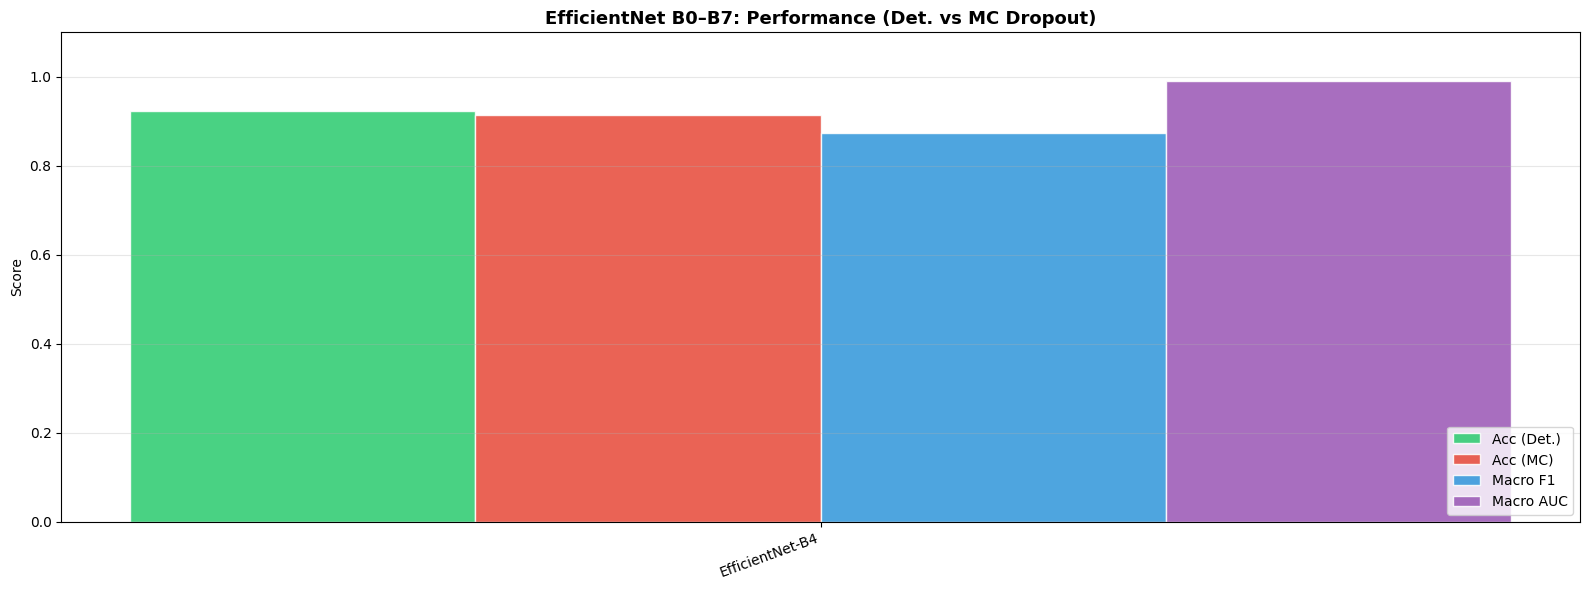

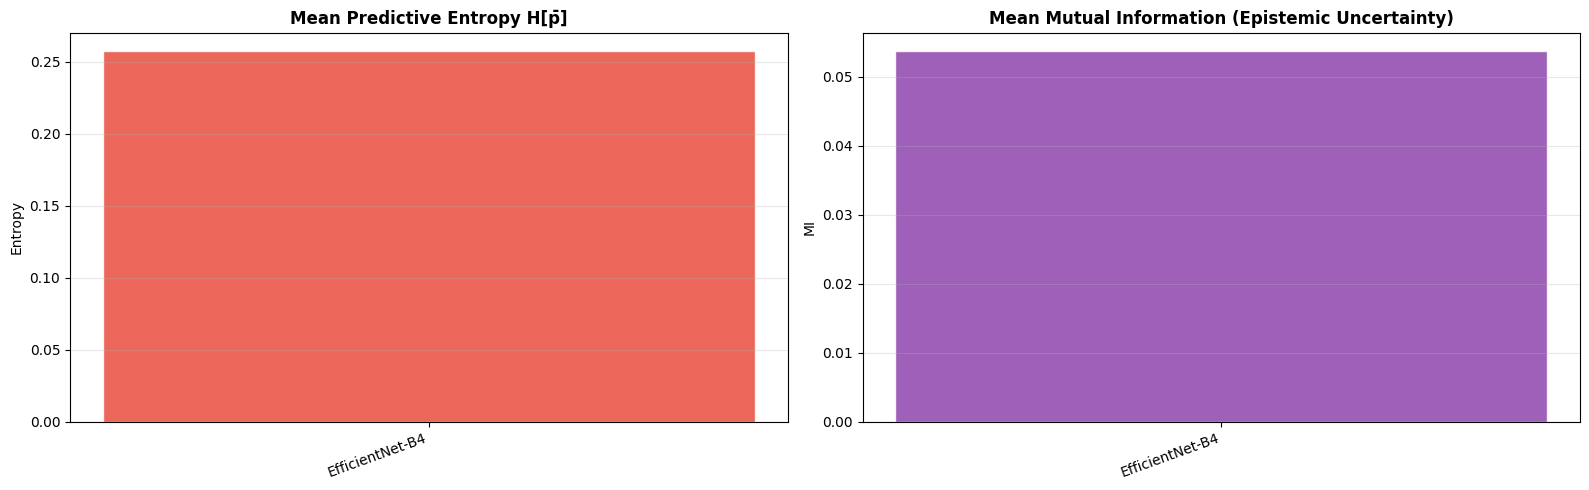

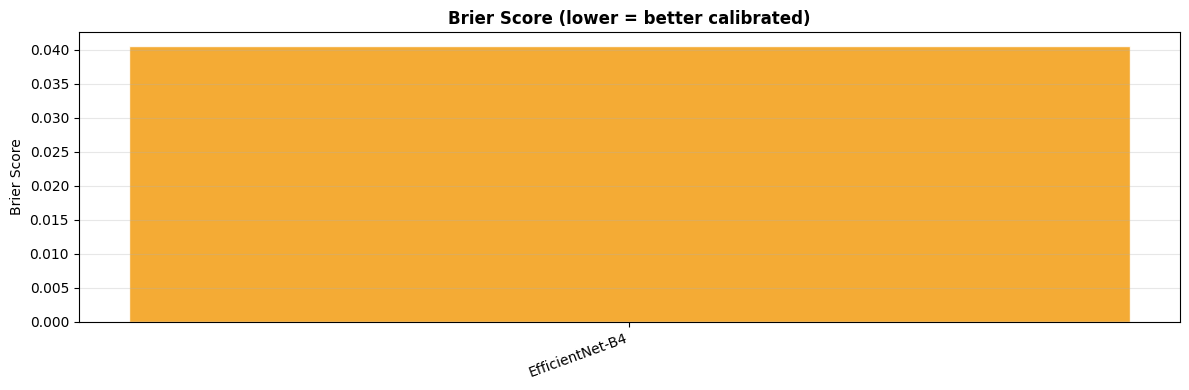

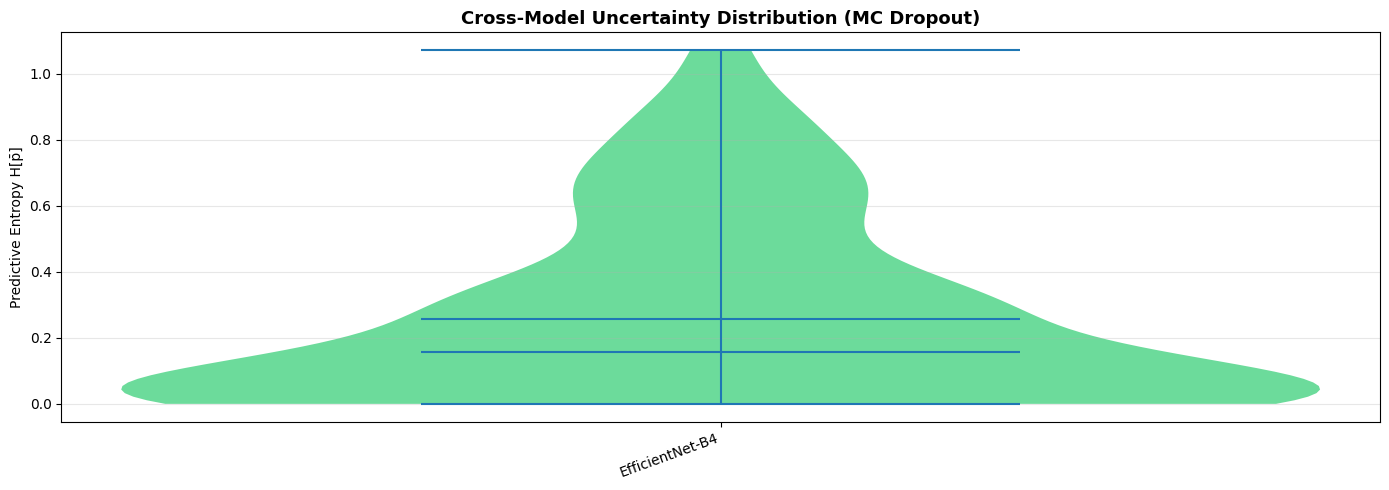

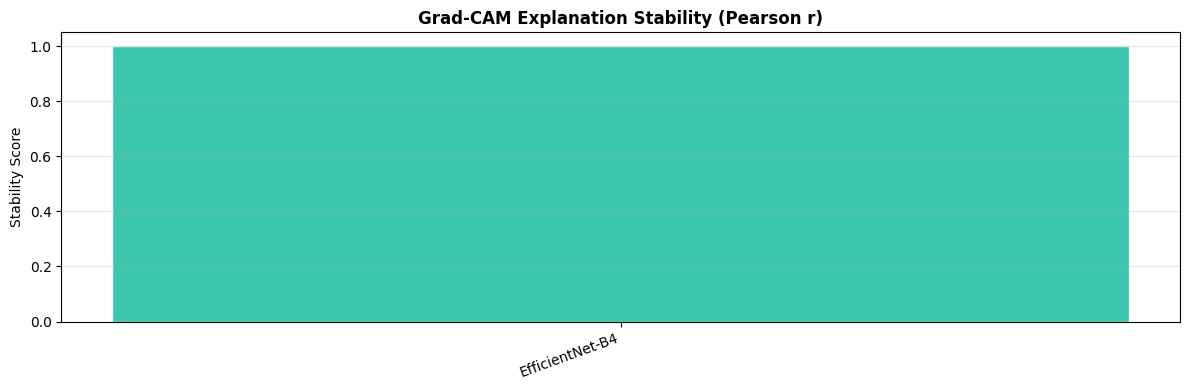

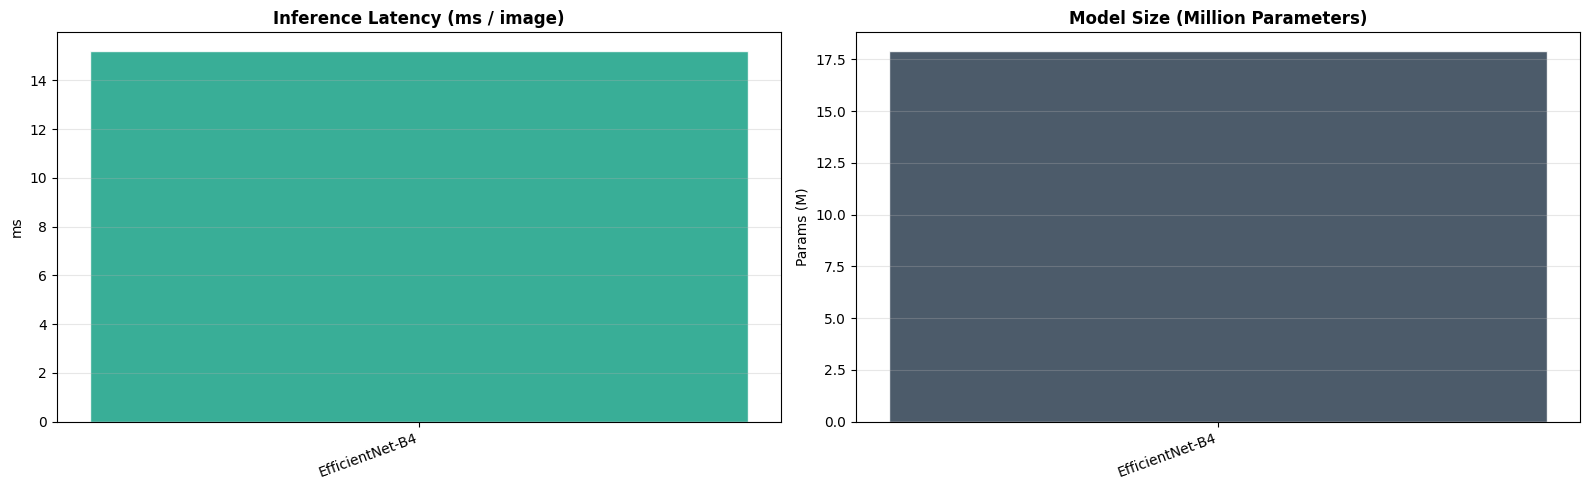

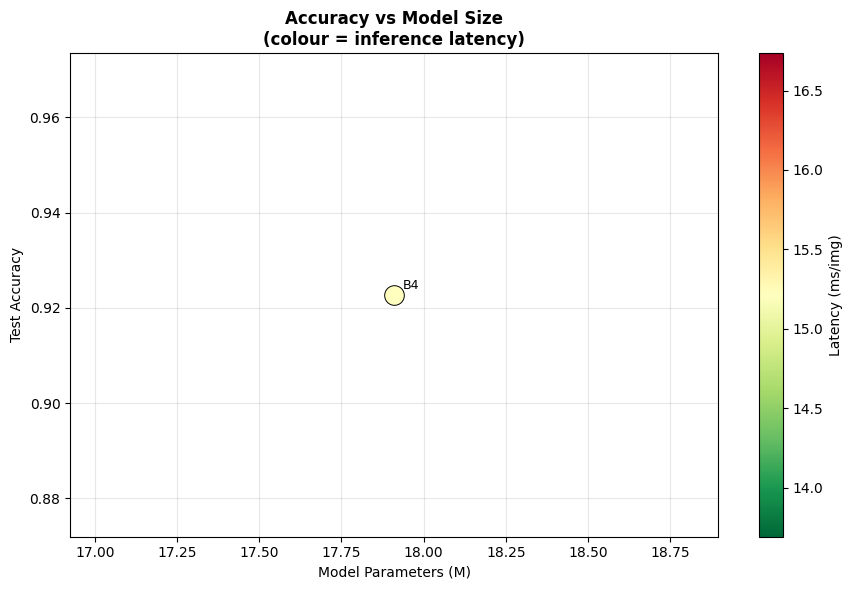

In [15]:
# ==========================================
# CELL 15: CROSS-MODEL COMPARISON CHARTS
# ==========================================

model_names = df['Model'].tolist()
x     = np.arange(len(model_names))
bar_w = 0.18
palette = ['#2ecc71','#e74c3c','#3498db','#9b59b6']

# ---- Chart 1: Accuracy / F1 / AUC / MC Accuracy ----
fig, ax = plt.subplots(figsize=(16, 6))
metrics = [('accuracy','Acc (Det.)'),('mc_accuracy','Acc (MC)'),
           ('macro_f1','Macro F1'),('macro_auc','Macro AUC')]
for j, (col, label) in enumerate(metrics):
    ax.bar(x + j*bar_w, df[col], bar_w, label=label,
           color=palette[j], alpha=0.87, edgecolor='white')
ax.set_xticks(x + bar_w*1.5)
ax.set_xticklabels(model_names, rotation=20, ha='right', fontsize=10)
ax.set_ylim(0, 1.10)
ax.set_ylabel('Score'); ax.set_title('EfficientNet B0–B7: Performance (Det. vs MC Dropout)',
                                     fontsize=13, fontweight='bold')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 2: Predictive Entropy + MI ----
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(model_names, df['mean_entropy'], color='#e74c3c', alpha=0.85, edgecolor='white')
axes[0].set_title('Mean Predictive Entropy H[p̄]', fontweight='bold')
axes[0].set_ylabel('Entropy'); axes[0].grid(axis='y', alpha=0.3)
axes[0].set_xticklabels(model_names, rotation=20, ha='right')
axes[1].bar(model_names, df['mean_mi'], color='#8e44ad', alpha=0.85, edgecolor='white')
axes[1].set_title('Mean Mutual Information (Epistemic Uncertainty)', fontweight='bold')
axes[1].set_ylabel('MI'); axes[1].grid(axis='y', alpha=0.3)
axes[1].set_xticklabels(model_names, rotation=20, ha='right')
plt.tight_layout(); plt.show()

# ---- Chart 3: Brier Score ----
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(model_names, df['mean_brier'], color='#f39c12', alpha=0.85, edgecolor='white')
ax.set_title('Brier Score (lower = better calibrated)', fontweight='bold')
ax.set_ylabel('Brier Score'); ax.grid(axis='y', alpha=0.3)
ax.set_xticklabels(model_names, rotation=20, ha='right')
plt.tight_layout(); plt.show()

# ---- Chart 4: Entropy violin across models ----
plot_entropy_violin(all_entropy)

# ---- Chart 5: Grad-CAM Stability ----
plot_stability(all_stability)

# ---- Chart 6: Latency + Parameters ----
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(model_names, df['latency_ms'], color='#16a085', alpha=0.85, edgecolor='white')
axes[0].set_title('Inference Latency (ms / image)', fontweight='bold')
axes[0].set_ylabel('ms'); axes[0].grid(axis='y', alpha=0.3)
axes[0].set_xticklabels(model_names, rotation=20, ha='right')
axes[1].bar(model_names, df['params_M'], color='#2c3e50', alpha=0.85, edgecolor='white')
axes[1].set_title('Model Size (Million Parameters)', fontweight='bold')
axes[1].set_ylabel('Params (M)'); axes[1].grid(axis='y', alpha=0.3)
axes[1].set_xticklabels(model_names, rotation=20, ha='right')
plt.tight_layout(); plt.show()

# ---- Chart 7: Accuracy vs Model Size (efficiency frontier) ----
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(df['params_M'], df['accuracy'],
                     c=df['latency_ms'], cmap='RdYlGn_r',
                     s=200, edgecolors='black', linewidths=0.7)
for _, row in df.iterrows():
    ax.annotate(row['Model'].replace('EfficientNet-',''),
                (row['params_M'], row['accuracy']),
                textcoords='offset points', xytext=(6, 4), fontsize=9)
plt.colorbar(scatter, ax=ax, label='Latency (ms/img)')
ax.set_xlabel('Model Parameters (M)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Accuracy vs Model Size\n(colour = inference latency)', fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


Cross-Model Uncertainty–XAI Correlation Heatmaps

Metric: Saliency Diffuseness (1 - Gini)


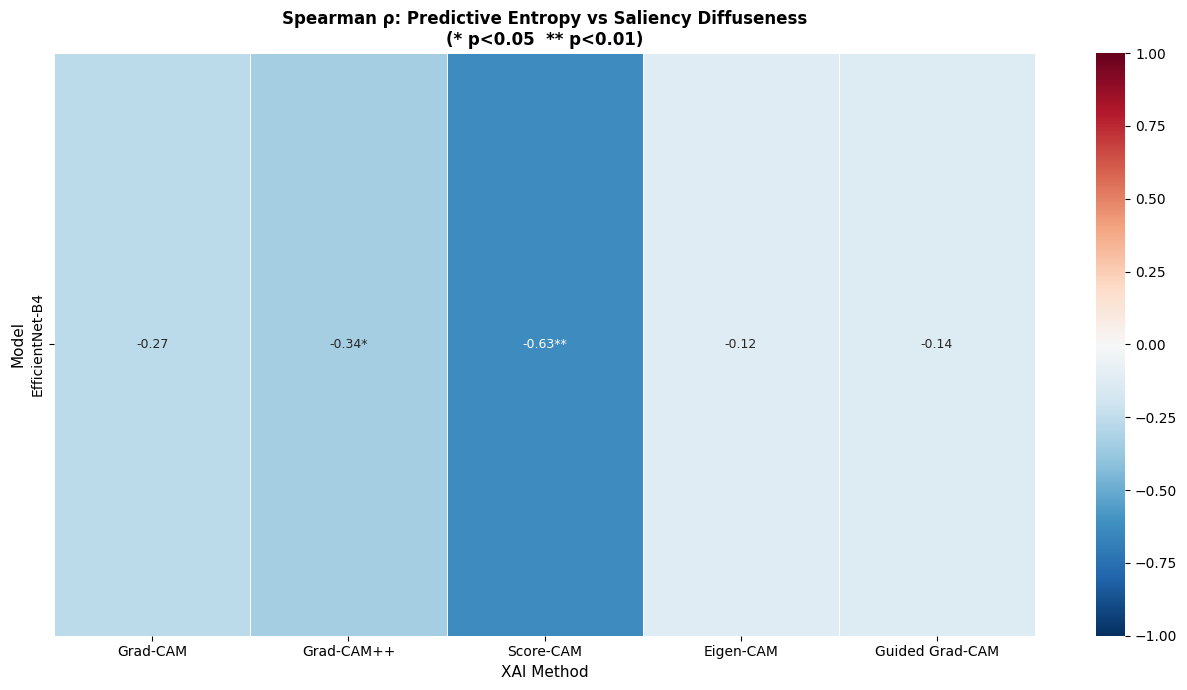


Metric: Saliency Entropy


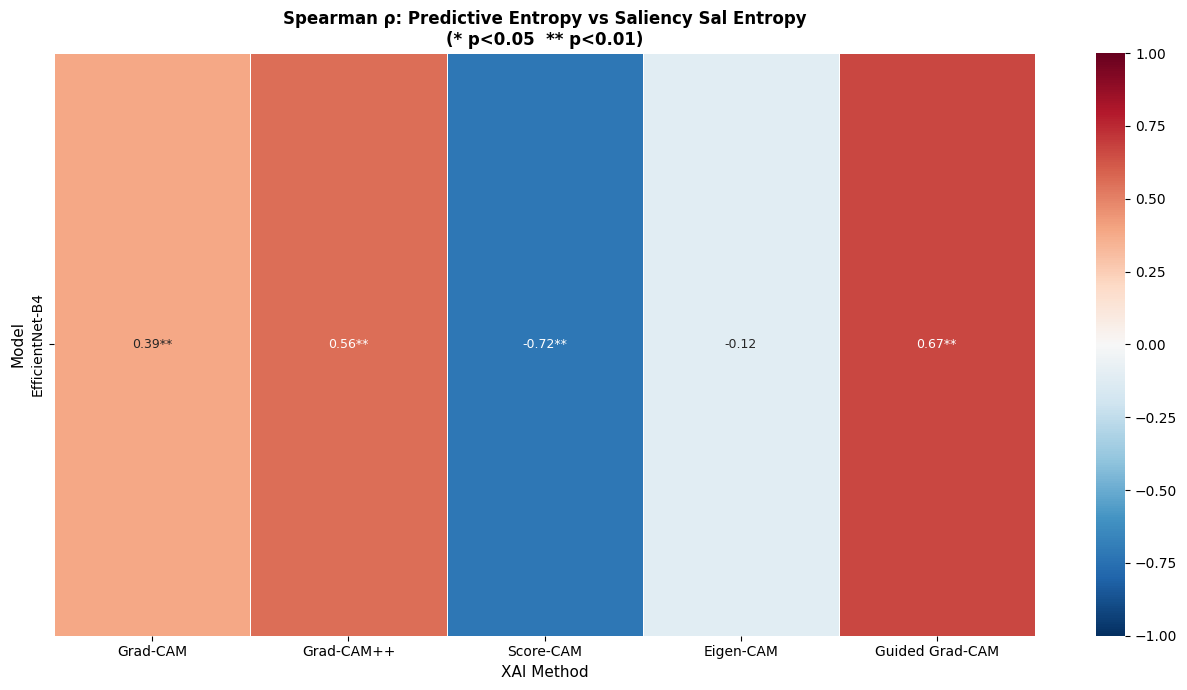


Metric: Effective Mass Fraction


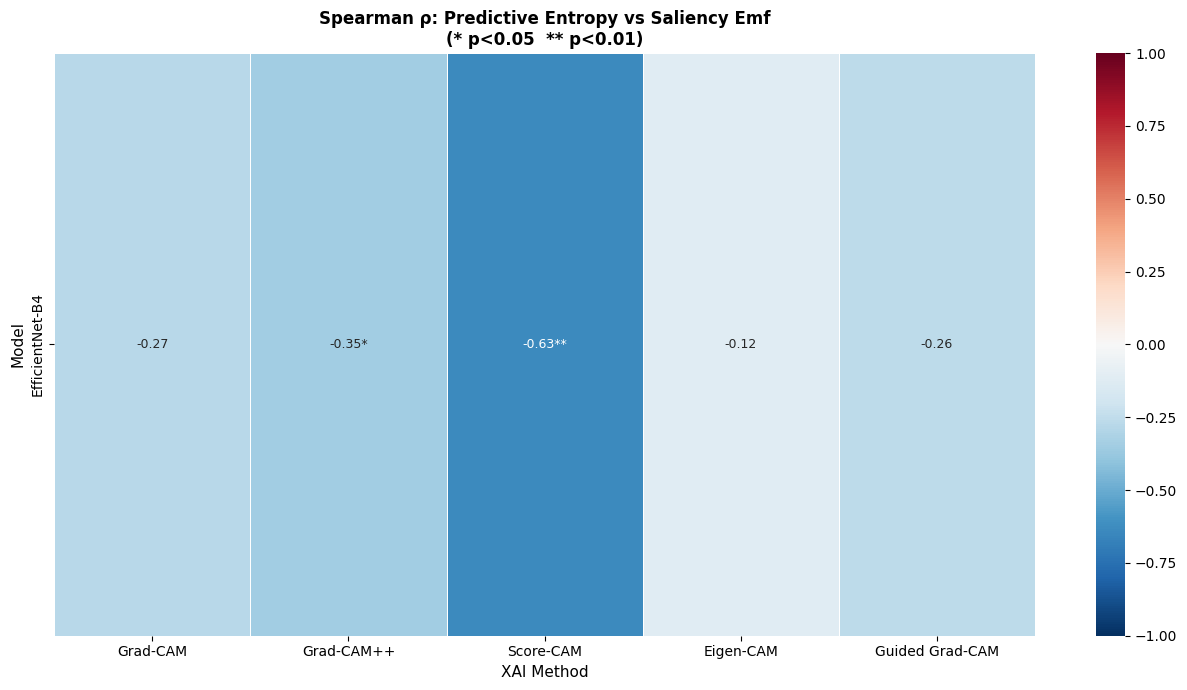


SUMMARY: Mean |ρ| per Model × XAI Method (Diffuseness metric)
                  Grad-CAM Grad-CAM++  Score-CAM  Eigen-CAM Guided Grad-CAM
Model                                                                      
EfficientNet-B4  -0.268 ns   -0.339 *  -0.631 **  -0.123 ns       -0.139 ns

ρ: Spearman correlation between entropy H[p̄] and saliency diffuseness
Positive ρ → higher uncertainty aligns with more diffuse saliency maps


In [16]:
# ==========================================
# CELL 16: CROSS-MODEL UNCERTAINTY–XAI HEATMAPS
#
# One heatmap per spatial metric:
#   rows = models, columns = XAI methods
#   cell = Spearman ρ (* p<0.05, ** p<0.01)
#
# Interpretation guide:
#   ρ > 0 → higher entropy → more diffuse map (expected)
#   ρ < 0 → higher entropy → more focal map (counter-intuitive)
#   |ρ| near 0 → no relationship between uncertainty and XAI
# ==========================================

print("Cross-Model Uncertainty–XAI Correlation Heatmaps")
print("=" * 65)

for metric_label, metric_key in [
    ('Saliency Diffuseness (1 - Gini)', 'diffuseness'),
    ('Saliency Entropy',                'sal_entropy'),
    ('Effective Mass Fraction',         'emf'),
]:
    print(f"\nMetric: {metric_label}")
    plot_correlation_heatmap(all_corr, metric=metric_key)

# ---- Summary table ----
print("\nSUMMARY: Mean |ρ| per Model × XAI Method (Diffuseness metric)")
xai_names = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM', 'Eigen-CAM', 'Guided Grad-CAM']
rows = []
for mn in all_corr:
    row = {'Model': mn}
    for xn in xai_names:
        try:
            rho, pval = all_corr[mn][xn]['diffuseness']
            sig = '**' if pval < 0.01 else ('*' if pval < 0.05 else 'ns')
            row[xn] = f"{rho:+.3f} {sig}"
        except Exception:
            row[xn] = 'N/A'
    rows.append(row)
df_corr_summary = pd.DataFrame(rows).set_index('Model')
print(df_corr_summary.to_string())
print("\nρ: Spearman correlation between entropy H[p̄] and saliency diffuseness")
print("Positive ρ → higher uncertainty aligns with more diffuse saliency maps")


In [17]:
# ==========================================
# CELL 17: FINAL RANKING & RECOMMENDATION
# Composite score balances classification performance AND
# uncertainty quality — same formula as the MobileNet notebook
# so the two model families can be compared directly:
#
# composite = 30% Accuracy
#           + 20% Macro F1
#           + 20% Macro AUC
#           + 10% Calibration  (1 - norm_brier)
#           + 10% Speed        (1 - norm_latency)
#           + 10% Stability
# ==========================================

df['norm_brier']    = (df['mean_brier'] - df['mean_brier'].min()) / \
                      (df['mean_brier'].max() - df['mean_brier'].min() + 1e-9)
df['norm_latency']  = (df['latency_ms'] - df['latency_ms'].min()) / \
                      (df['latency_ms'].max() - df['latency_ms'].min() + 1e-9)
df['norm_stability']= (df['stability']  - df['stability'].min())  / \
                      (df['stability'].max()  - df['stability'].min() + 1e-9)

df['composite'] = (
    0.30 * df['accuracy']             +
    0.20 * df['macro_f1']             +
    0.20 * df['macro_auc']            +
    0.10 * (1 - df['norm_brier'])     +
    0.10 * (1 - df['norm_latency'])   +
    0.10 * df['norm_stability']
).round(4)

df_rank = df[['Model','accuracy','mc_accuracy','macro_f1','macro_auc',
              'mean_entropy','mean_brier','latency_ms','stability','composite']]\
            .sort_values('composite', ascending=False).reset_index(drop=True)
df_rank.index += 1
df_rank.index.name = 'Rank'

print("\n" + "="*100)
print("  FINAL RANKING — Uncertainty-Aware EfficientNet B0-B7")
print("  IQ-OTH/NCCD Lung Cancer Detection")
print("="*100)
print(df_rank.round(4).to_string())
print("\nComposite = 30% Acc + 20% F1 + 20% AUC + 10% Calibration + 10% Speed + 10% Stability")

winner = df_rank.iloc[0]
print("\n" + "-"*100)
print(f"  RECOMMENDED MODEL : {winner['Model']}")
print(f"  Det. Accuracy     : {winner['accuracy']:.4f}")
print(f"  MC Accuracy       : {winner['mc_accuracy']:.4f}")
print(f"  Macro F1          : {winner['macro_f1']:.4f}")
print(f"  Macro AUC         : {winner['macro_auc']:.4f}")
print(f"  Mean Entropy      : {winner['mean_entropy']:.4f}")
print(f"  Brier Score       : {winner['mean_brier']:.4f}")
print(f"  Latency           : {winner['latency_ms']:.2f} ms/image")
print("-"*100)



  FINAL RANKING — Uncertainty-Aware EfficientNet B0-B7
  IQ-OTH/NCCD Lung Cancer Detection
                Model  accuracy  mc_accuracy  macro_f1  macro_auc  mean_entropy  mean_brier  latency_ms  stability  composite
Rank                                                                                                                         
1     EfficientNet-B4    0.9227       0.9136    0.8735     0.9903        0.2575      0.0405     15.2139     0.9999     0.8496

Composite = 30% Acc + 20% F1 + 20% AUC + 10% Calibration + 10% Speed + 10% Stability

----------------------------------------------------------------------------------------------------
  RECOMMENDED MODEL : EfficientNet-B4
  Det. Accuracy     : 0.9227
  MC Accuracy       : 0.9136
  Macro F1          : 0.8735
  Macro AUC         : 0.9903
  Mean Entropy      : 0.2575
  Brier Score       : 0.0405
  Latency           : 15.21 ms/image
---------------------------------------------------------------------------------------------

In [19]:
# ==========================================
# CELL 18: SAVE ALL RESULTS TO GOOGLE DRIVE
# ==========================================
base_path = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/'

# Classification + uncertainty metrics
df_rank.to_csv(base_path + 'efficientnet_uncertainty_ranking-B4.csv')
print(f"Ranking saved to: {base_path}efficientnet_uncertainty_ranking-B4.csv")

# Uncertainty–XAI correlation summary
df_corr_summary.to_csv(base_path + 'efficientnet_uncertainty_xai_correlation-B4.csv')
print(f"Correlation table saved to: {base_path}efficientnet_uncertainty_xai_correlation-B4.csv")

print("\nAll results saved.")


Ranking saved to: /content/drive/My Drive/Kaggle/IQ-OTH-NCCD/efficientnet_uncertainty_ranking-B4.csv
Correlation table saved to: /content/drive/My Drive/Kaggle/IQ-OTH-NCCD/efficientnet_uncertainty_xai_correlation-B4.csv

All results saved.
